# Phase 3: Features + classification (evangeline, patient 29)

My patient's liver has almost no dark spots apart from the tumour, so dark-spot candidates would not give me a healthy class. Instead my regions come from SLIC superpixels: the liver is cut into about 20 small patches of similar brightness.

A patch is tumour if at least 50% of it is inside the ground-truth tumour, and healthy if it has no tumour pixels at all (I keep at most 3 per slice). Mixed patches are skipped.

My features are shape, GLCM (0/45/90/135 degrees), first-order HU, and my own set, Laws texture energy. My classifier is a decision tree; the max depth is tuned by grouped 5-fold CV and kept small so the rules stay readable.

## Step 0: Setup

Imports, folders and the loader (raw CT, enhanced slice, ground-truth liver, ground-truth tumour).

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew, kurtosis, mannwhitneyu
from skimage.segmentation import slic, mark_boundaries
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

NAME = "evangeline"
SLICES = "../data/slices/" + NAME                   # raw CT (HU) + ground-truth masks
ENH = "../phase1/outputs_evangeline/enhanced"       # Phase 1 output
OUT = "outputs_evangeline"
FIGS = "../report/figures/evangeline"
os.makedirs(OUT, exist_ok=True)

# list the slice ids (e.g. p29_s60) from the enhanced images
slice_ids = []
for f in glob.glob(ENH + "/*_enh.png"):
    slice_ids.append(os.path.basename(f).replace("_enh.png", ""))
slice_ids = sorted(slice_ids)
print(len(slice_ids), "slices")


def load(sid):
    ct = np.load(SLICES + "/" + sid + "_ct.npy")                              # raw HU (for first-order stats)
    enhanced_img = cv2.imread(ENH + "/" + sid + "_enh.png", 0)                # enhanced 0-255 (for texture)
    liver_mask = cv2.imread(SLICES + "/" + sid + "_liver.png", 0) > 0         # ground-truth liver
    tumour_mask = cv2.imread(SLICES + "/" + sid + "_tumour.png", 0) > 0       # ground-truth tumour
    return ct, enhanced_img, liver_mask, tumour_mask

22 slices


## Step 1: Feature functions (Chapter 10-11)

Area, perimeter and compactness come from the Chapter 10-11 regional descriptors; circularity, eccentricity and solidity are extensions. The GLCM (Chapter 10-11) is measured at 4 angles, and the first-order features are the statistical moments of the HU values.

In [2]:
# ---- Chapter 10-11: simple regional descriptors (area, perimeter, compactness) ----
# circularity, eccentricity and solidity are extensions of these (not in the slides)
def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area = r.area
    perim = max(r.perimeter, 1e-6)
    feats = {}
    feats["area"] = area
    feats["perimeter_area_ratio"] = perim / area
    feats["circularity"] = 4 * np.pi * area / perim ** 2      # 1 = perfect circle
    feats["compactness"] = perim ** 2 / area                  # Chapter 10-11: perimeter^2 / area
    feats["eccentricity"] = r.eccentricity                    # 0 = circle, 1 = line
    feats["solidity"] = r.solidity                            # area / convex hull area
    return feats

In [3]:
# ---- Chapter 10-11: GLCM (grey level co-occurrence matrix), 2nd-order texture ----
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]


def glcm_features(enhanced_img, mask, levels=32, per_angle=False):
    # GLCM texture inside the region only (pixels outside the region are ignored)
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch = enhanced_img[r0:r1, c0:c1].astype(int)
    m = mask[r0:r1, c0:c1]

    # quantise to 1..levels inside the region, 0 outside
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)
    P = P[1:, 1:, :, :].astype(float)                                      # drop pairs touching "outside"
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)           # normalise: counts -> probabilities

    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])                     # one value per angle
        if per_angle:
            for i in range(4):
                feats[f"glcm_{prop}_{ANGLE_NAMES[i]}"] = vals[i]
        else:
            feats[f"glcm_{prop}"] = vals.mean()

    # entropy of the GLCM at each angle
    ent = []
    for k in range(4):
        p_k = P[:, :, 0, k]
        nonzero = p_k[p_k > 0]
        ent.append(-(nonzero * np.log2(nonzero)).sum())
    if per_angle:
        for i in range(4):
            feats[f"glcm_entropy_{ANGLE_NAMES[i]}"] = ent[i]
    else:
        feats["glcm_entropy"] = np.mean(ent)
    return feats


def glcm_angle_table(enhanced_img, mask):
    # one column per angle, one row per GLCM property
    t = pd.Series(glcm_features(enhanced_img, mask, per_angle=True))
    table = {}
    for a in ANGLE_NAMES:
        keys = []
        for k in t.index:
            if k.endswith("_" + a):
                keys.append(k)
        table[a] = t[keys].values
    table = pd.DataFrame(table, index=["energy", "contrast", "homogeneity", "correlation", "entropy"])
    return table.round(3)

In [4]:
# ---- Chapter 10-11: histogram based 1st-order statistics (statistical moments) of the HU values ----
def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    feats = {}
    feats["mean_HU"] = hu.mean()
    feats["variance_HU"] = hu.var()
    if hu.std() > 0:
        feats["skewness"] = skew(hu)
        feats["kurtosis"] = kurtosis(hu)
    else:
        feats["skewness"] = 0.0
        feats["kurtosis"] = 0.0
    return feats

## Step 2: SLIC superpixels (extension of Chapter 7)

SLIC groups similar neighbouring pixels, which is region-based segmentation (Chapter 7, slide 13), but the SLIC algorithm itself is not in the slides. After labelling the patches I show the superpixels of the slice with the biggest tumour.

In [5]:
# ---- candidate regions: SLIC superpixels inside the liver ----
# SLIC groups similar neighbouring pixels (region-based segmentation, Chapter 7 slide 13);
# the SLIC algorithm itself is an extension, it is not in the slides
MIN_AREA = 10
N_SEGMENTS = 20
rng = np.random.default_rng(42)


def superpixels(enhanced_img, liver_mask):
    # groups liver pixels into ~20 compact patches of similar brightness
    return slic(enhanced_img, n_segments=N_SEGMENTS, compactness=0.1, mask=liver_mask, channel_axis=None, start_label=1)


# label every patch: tumour (>= 50% inside the true tumour), healthy (no tumour pixels, max 3 per slice)
rois = []                      # (slice id, region mask, label)  label: 1 = tumour, 0 = healthy
for sid in slice_ids:
    ct, enhanced_img, liver_mask, tumour_mask = load(sid)
    sp = superpixels(enhanced_img, liver_mask)
    healthy = []
    for i in range(1, sp.max() + 1):
        m = sp == i
        if m.sum() < MIN_AREA:
            continue
        frac = (m & tumour_mask).sum() / m.sum()
        if frac >= 0.5:
            rois.append((sid, m, 1))
        elif frac == 0:
            healthy.append(m)
    # pick at most 3 healthy patches at random
    order = rng.permutation(len(healthy))
    for i in order[:3]:
        rois.append((sid, healthy[i], 0))

roi_labels = []
for sid, m, roi_label in rois:
    roi_labels.append(roi_label)
roi_labels = np.array(roi_labels)
print(len(rois), "regions:", (roi_labels == 1).sum(), "tumour,", (roi_labels == 0).sum(), "healthy")

118 regions: 52 tumour, 66 healthy


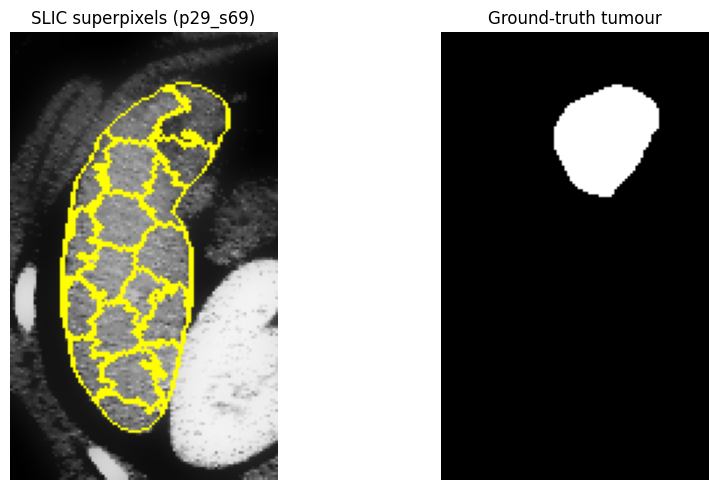

In [6]:
# show the superpixels of the slice with the biggest tumour (saved for the report)
sid = slice_ids[0]
biggest = -1
for s in slice_ids:
    ct, enhanced_img, liver_mask, tumour_mask = load(s)
    if tumour_mask.sum() > biggest:
        biggest = tumour_mask.sum()
        sid = s
ct, enhanced_img, liver_mask, tumour_mask = load(sid)

# zoom on the liver with a 20 pixel border
ys, xs = np.where(liver_mask)
y0 = max(ys.min() - 20, 0)
y1 = ys.max() + 20
x0 = max(xs.min() - 20, 0)
x1 = xs.max() + 20

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(mark_boundaries(enhanced_img, superpixels(enhanced_img, liver_mask))[y0:y1, x0:x1])
ax[0].set_title(f"SLIC superpixels ({sid})")
ax[1].imshow(tumour_mask[y0:y1, x0:x1], cmap="gray")
ax[1].set_title("Ground-truth tumour")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p3_superpixels.png", dpi=120)
plt.show()

In [7]:
# GLCM table at the 4 angles for the largest tumour patch (for the report)
largest = -1
for roi in rois:
    if roi[2] == 1 and roi[1].sum() > largest:
        largest = roi[1].sum()
        sid = roi[0]
        m = roi[1]
ct, enhanced_img, liver_mask, tumour_mask = load(sid)
glcm_example = glcm_angle_table(enhanced_img, m)

print(f"GLCM at 4 angles, largest tumour patch ({sid}):")
print(glcm_example)
glcm_example.to_csv(FIGS + "/" + NAME + "_glcm_table.csv")

GLCM at 4 angles, largest tumour patch (p29_s74):
                 0     45     90    135
energy       0.211  0.209  0.212  0.203
contrast     2.399  2.622  2.701  2.956
homogeneity  0.552  0.536  0.559  0.514
correlation  0.554  0.485  0.491  0.460
entropy      5.043  5.051  5.080  5.151


## Step 3: My own features, Laws texture energy

Laws texture energy is an extension of the Chapter 10-11 texture descriptors. Each Laws mask is a 5x5 convolution mask (Chapter 3), made from two of the 1D masks Level, Edge, Spot and Ripple. I remove the local brightness first (15x15 mean), then each mask picks up one kind of fine texture, and the energy is the mean absolute response inside the region. L5E5 and E5L5 (and so on) are averaged so the feature does not depend on direction.

In [8]:
# ---- Laws texture energy: evangeline's own feature set ----
# extension of the Chapter 10-11 texture descriptors; each Laws mask is a 5x5 convolution mask (Chapter 3)
# Laws' 1D masks: Level (average), Edge, Spot, Ripple. A 2D mask = outer product of two of them.
L5 = [1, 4, 6, 4, 1]
E5 = [-1, -2, 0, 2, 1]
S5 = [-1, 0, 2, 0, -1]
R5 = [1, -4, 6, -4, 1]
LAWS_PAIRS = {}
LAWS_PAIRS["L5E5"] = (L5, E5)
LAWS_PAIRS["L5S5"] = (L5, S5)
LAWS_PAIRS["E5E5"] = (E5, E5)
LAWS_PAIRS["S5S5"] = (S5, S5)
LAWS_PAIRS["R5R5"] = (R5, R5)


def laws_features(enhanced_img, mask):
    # the local brightness is removed first (15x15 mean), then each 5x5 Laws mask picks up one kind of
    # fine texture (edges, spots, ripples); the energy is the mean absolute response inside the region.
    # L5E5 and E5L5 (etc.) are averaged so the feature does not depend on direction
    img = enhanced_img.astype(np.float64) - cv2.blur(enhanced_img.astype(np.float64), (15, 15))
    feats = {}
    for name in LAWS_PAIRS:
        a, b = LAWS_PAIRS[name]
        k = np.outer(a, b).astype(np.float64)
        response = np.abs(cv2.filter2D(img, -1, k))
        if a != b:
            response = (response + np.abs(cv2.filter2D(img, -1, k.T))) / 2          # both directions
        feats[f"laws_{name}"] = response[mask].mean()
    return feats

In [9]:
# measure every feature for every region -> one row per region
cache = {}
feature_rows = []
for sid, m, roi_label in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enhanced_img, liver_mask, tumour_mask = cache[sid]
    row = {}
    row["slice"] = sid
    row["label"] = roi_label
    for feats in [shape_features(m), glcm_features(enhanced_img, m), first_order_features(ct, m), laws_features(enhanced_img, m)]:
        for key in feats:
            row[key] = feats[key]
    feature_rows.append(row)

features = pd.DataFrame(feature_rows)
features.to_csv(OUT + "/phase3_features.csv", index=False)

# mean of every feature, healthy vs tumour
class_means = features.groupby("label").mean(numeric_only=True)
class_means = class_means.T.round(3)
class_means = class_means.rename(columns={0: "healthy", 1: "tumour"})
print(class_means)

label                  healthy   tumour
area                   309.833  262.096
perimeter_area_ratio     0.342    0.351
circularity              0.423    0.489
compactness             32.389   28.785
eccentricity             0.729    0.729
solidity                 0.765    0.774
glcm_energy              0.165    0.179
glcm_contrast            9.394    4.896
glcm_homogeneity         0.400    0.458
glcm_correlation         0.374    0.498
glcm_entropy             5.786    5.453
mean_HU                 95.451   76.002
variance_HU           1012.109  610.852
skewness                -0.100   -0.384
kurtosis                 4.231    2.067
laws_L5E5              645.110  538.759
laws_L5S5              362.587  268.023
laws_E5E5              162.285  141.265
laws_S5S5               75.000   61.495
laws_R5R5              626.086  530.138


## Step 4: Grouped train / test split

Regions from the same slice, and from neighbouring slices, look almost the same, so they must not end up on both sides of the split. We group by slice and join consecutive slices into blocks of 3 (or 2) when there are still at least 5 training groups for 5-fold CV.

In [10]:
X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- groups: every region from the same slice stays on the same side of the split ----
# Neighbouring slices show the same tumour, so a random split of regions would put near-copies in train AND test.
# Consecutive slices are joined into blocks of 3 (or 2) only if that still leaves >= 5 training groups for 5-fold CV.
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position_of = {}
i = 0
for s in sorted(slice_no.unique()):
    position_of[s] = i
    i = i + 1
position = slice_no.map(position_of).values      # 0, 1, 2, ... along the scan


def grouped_split(groups):
    # 70/30 split by group. Groups differ in size, so try 50 seeds and keep the one whose test part is closest
    # to 30% of the REGIONS (only sizes are looked at, never the scores). Needs >= 5 train groups + both classes in test
    best_split = None
    best_gap = 1.0
    for seed in range(50):
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
        tr, te = next(splitter.split(X, y, groups))
        gap = abs(len(te) / len(y) - 0.3)
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and gap < best_gap:
            best_split = (tr, te)
            best_gap = gap
    return best_split


for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train = X[idx_train]
X_test = X[idx_test]
y_train = y[idx_train]
y_test = y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

block = 3 slice(s) per group | train: 5 groups, 83 regions | test: 3 groups, 35 regions (30% of all regions)


## Step 5: Decision tree (extension of Chapter 12-13)

I chose a decision tree because it is a flowchart of yes/no questions on the features that I can actually read. It is an extension of the Chapter 12-13 decision-theoretic classifiers. Grouped 5-fold CV on the 70% train part picks the max depth from 2 to 6.

In [11]:
# ---- classifier: decision tree (extension of the Chapter 12-13 decision-theoretic classifiers) ----
# decision tree: a flowchart of yes/no questions on the features
# 5-fold grouped cross-validation on the 70% TRAIN part only picks the max depth; the 30% test part stays untouched
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tree_pipeline = make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42))
search = GridSearchCV(tree_pipeline, {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["decisiontreeclassifier__max_depth"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned max depth = {best}  (tried [2, 3, 4, 5, 6])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")

cv_summary = {}
cv_summary["tuned max depth"] = best
cv_summary["group block (slices)"] = BLOCK
cv_summary["CV accuracy mean"] = cv["test_accuracy"].mean()
cv_summary["CV accuracy std"] = cv["test_accuracy"].std()
cv_summary["CV F1 mean"] = cv["test_f1"].mean()
cv_summary["CV F1 std"] = cv["test_f1"].std()

tuned max depth = 2  (tried [2, 3, 4, 5, 6])
5-fold grouped CV on train: accuracy 0.978 +/- 0.027  folds: [0.947 1.    0.941 1.    1.   ]
                            F1       0.976 +/- 0.030  folds: [0.947 1.    0.933 1.    1.   ]


## Step 6: Test results

Accuracy, sensitivity (recall), specificity and F1 on the 30% test set, the 95% bootstrap confidence intervals (2000 resamples over the test groups) and the confusion matrix.

In [12]:
# ---- test set: accuracy, sensitivity (recall), specificity, F1 ----
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {}
metrics["accuracy"] = accuracy_score(y_test, y_pred)
if tp + fn:
    metrics["sensitivity (recall)"] = tp / (tp + fn)     # tumours correctly found
else:
    metrics["sensitivity (recall)"] = 0
if tn + fp:
    metrics["specificity"] = tn / (tn + fp)              # healthy correctly cleared
else:
    metrics["specificity"] = 0
metrics["F1"] = f1_score(y_test, y_pred, zero_division=0)

print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k in metrics:
    print(f"  {k:22s} {metrics[k]:.3f}")

Test set: 35 regions (14 tumour, 21 healthy)
  accuracy               0.943
  sensitivity (recall)   0.929
  specificity            0.952
  F1                     0.929


In [13]:
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    if tp + fn:
        sensitivity = tp / (tp + fn)
    else:
        sensitivity = np.nan
    if tn + fp:
        specificity = tn / (tn + fp)
    else:
        specificity = np.nan
    return [accuracy_score(t, p), sensitivity, specificity, f1_score(t, p, zero_division=0)]


boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
unique_test_groups = np.unique(test_groups)
boot = []
for _ in range(2000):
    chosen_groups = boot_rng.choice(unique_test_groups, len(unique_test_groups))
    parts = []
    for g in chosen_groups:
        parts.append(np.where(test_groups == g)[0])
    pick = np.concatenate(parts)
    boot.append(scores(y_test[pick], y_pred[pick]))
lo = np.nanpercentile(boot, 2.5, axis=0)
hi = np.nanpercentile(boot, 97.5, axis=0)

ci = {}
print("95% bootstrap CI (test groups resampled):")
metric_names = list(metrics)
for i in range(len(metric_names)):
    k = metric_names[i]
    ci[f"{k} CI low"] = lo[i]
    ci[f"{k} CI high"] = hi[i]
    print(f"  {k:22s} [{lo[i]:.3f}, {hi[i]:.3f}]")

# one row with every number, saved for the report
all_metrics = {}
for k in metrics:
    all_metrics[k] = metrics[k]
for k in cv_summary:
    all_metrics[k] = cv_summary[k]
for k in ci:
    all_metrics[k] = ci[k]
pd.DataFrame([all_metrics]).to_csv(OUT + "/phase3_metrics.csv", index=False)

95% bootstrap CI (test groups resampled):
  accuracy               [0.833, 1.000]
  sensitivity (recall)   [0.667, 1.000]
  specificity            [0.889, 1.000]
  F1                     [0.000, 1.000]


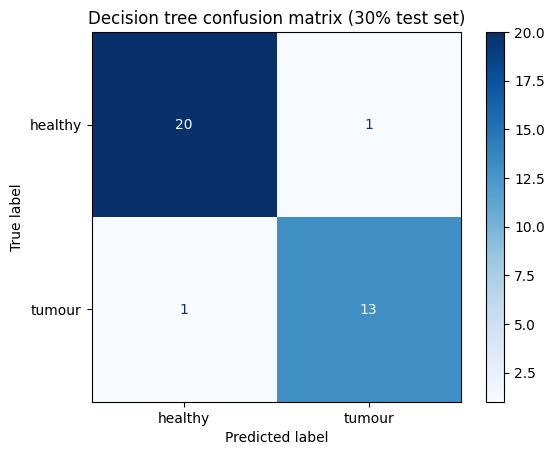

In [14]:
# confusion matrix of the test set (saved for the report)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(cm, display_labels=["healthy", "tumour"])
cm_display.plot(cmap="Blues")
plt.title("Decision tree confusion matrix (30% test set)")
plt.savefig(FIGS + "/" + NAME + "_p3_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 7: Failed cases and the final tree

For each wrong test region I list the 3 features that are most unlike its true class. Then the tree is trained on all regions, drawn, and saved for the app.

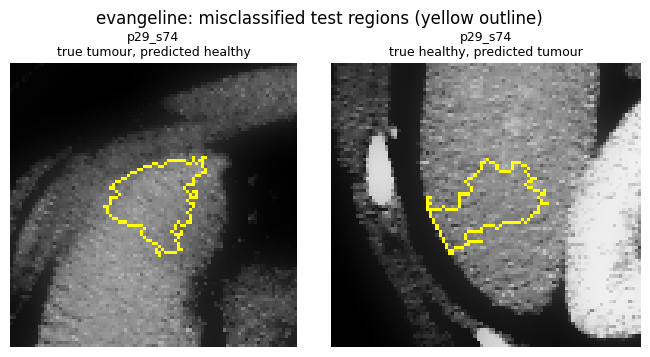

# Phase 3 failed cases: evangeline

Test set: 35 regions, **2 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |
|---|---|---|---|---|---|
| p29_s74 | tumour | healthy | 627 | 101 | area 627 (z +3.5), laws_L5E5 316 (z -2.6), laws_L5S5 184 (z -2.3) |
| p29_s74 | healthy | tumour | 578 | 93 | area 578 (z +3.0), perimeter_area_ratio 0.247 (z -1.3), laws_L5E5 438 (z -1.3) |


In [15]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = "../report/failed_cases/" + NAME
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}

lines = []
lines.append(f"# Phase 3 failed cases: {NAME}")
lines.append("")
lines.append(f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.")
lines.append("")
lines.append("| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |")
lines.append("|---|---|---|---|---|---|")

feat_cols = list(features.columns[2:])
train_feats = features.iloc[idx_train]
for i in wrong:
    sid, m, true_label = rois[i]
    row = features.iloc[i]
    # measured reason: the 3 features where this region is most unlike the TRAINING regions of its true class (|z-score|)
    own_class = train_feats[train_feats.label == true_label][feat_cols]
    z = (row[feat_cols] - own_class.mean()) / (own_class.std() + 1e-9)
    z = z.astype(float)
    top = z.abs().sort_values(ascending=False).index[:3]
    why_parts = []
    for f in top:
        why_parts.append(f"{f} {row[f]:.3g} (z {z[f]:+.1f})")
    why = ", ".join(why_parts)
    lines.append(f"| {sid} | {names[true_label]} | {names[1 - true_label]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")

if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for j in range(len(wrong)):
        sid, m, true_label = rois[wrong[j]]
        ct, enhanced_img, liver_mask, tumour_mask = load(sid)
        rgb = cv2.cvtColor(enhanced_img, cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        # crop around the region with a 30 pixel border
        ys, xs = np.where(m)
        y0 = max(ys.min() - 30, 0)
        y1 = ys.max() + 30
        x0 = max(xs.min() - 30, 0)
        x1 = xs.max() + 30
        axes[0][j].imshow(rgb[y0:y1, x0:x1])
        axes[0][j].axis("off")
        axes[0][j].set_title(f"{sid}\ntrue {names[true_label]}, predicted {names[1 - true_label]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout()
    plt.savefig(FAILED + "/" + NAME + "_p3_misclassified.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")

report_text = "\n".join(lines)
with open(FAILED + "/" + NAME + "_phase3_failed_cases.md", "w") as fh:
    fh.write(report_text)
print(report_text)

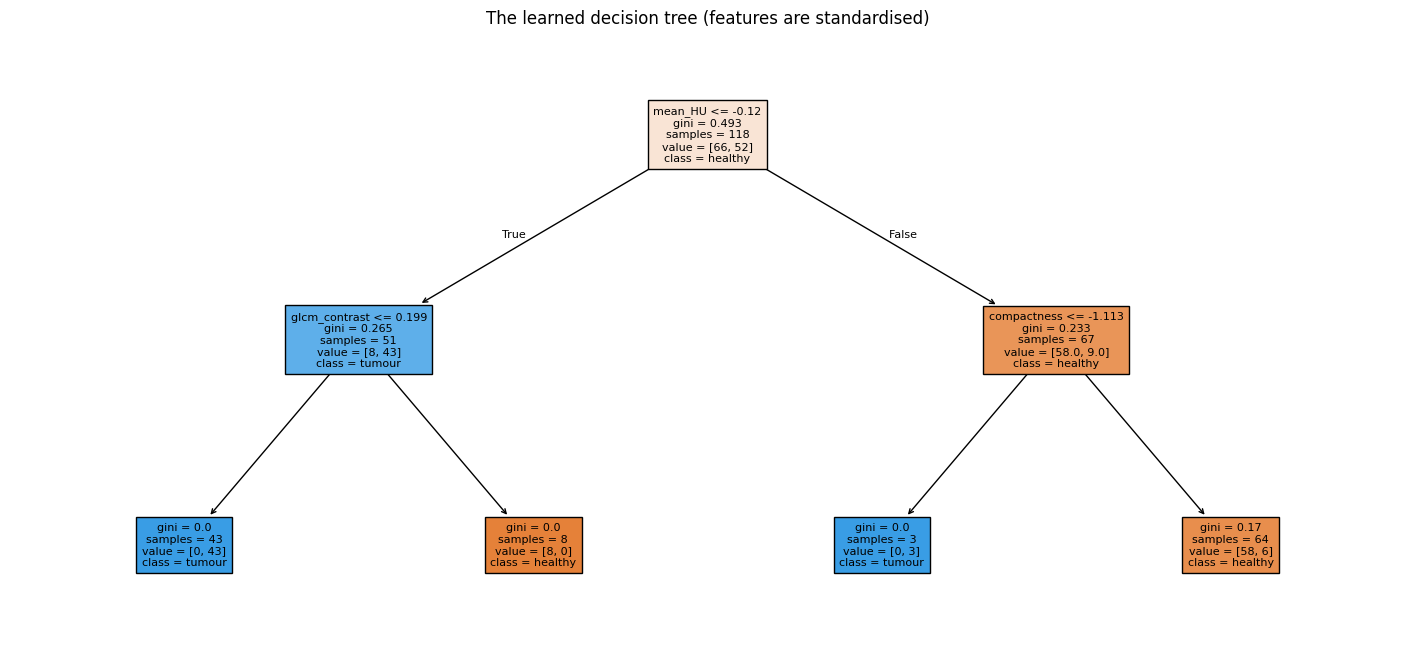

saved model to outputs_evangeline/tree_model.joblib


In [16]:
# final model trained on all regions
model.fit(X, y)

# draw the learned tree (saved for the report)
plt.figure(figsize=(18, 8))
plot_tree(model[-1], feature_names=list(features.columns[2:]), class_names=["healthy", "tumour"], filled=True, fontsize=8)
plt.title("The learned decision tree (features are standardised)")
plt.savefig(FIGS + "/" + NAME + "_p3_decision_tree.png", dpi=120, bbox_inches="tight")
plt.show()

# save the model for the app
saved = {}
saved["model"] = model
saved["feature_names"] = list(features.columns[2:])
joblib.dump(saved, OUT + "/tree_model.joblib")
print("saved model to", OUT + "/tree_model.joblib")

## Step 8: Feature analysis

Finally I look at the features themselves. I draw box plots of each feature for healthy vs tumour, run a Mann-Whitney U test per feature (it checks whether the classes differ and does not need a normal distribution), and do an ablation: the same tuned classifier trained on one feature group at a time, with the same grouped split (grouped 5-fold CV on the 70% plus the untouched 30%).

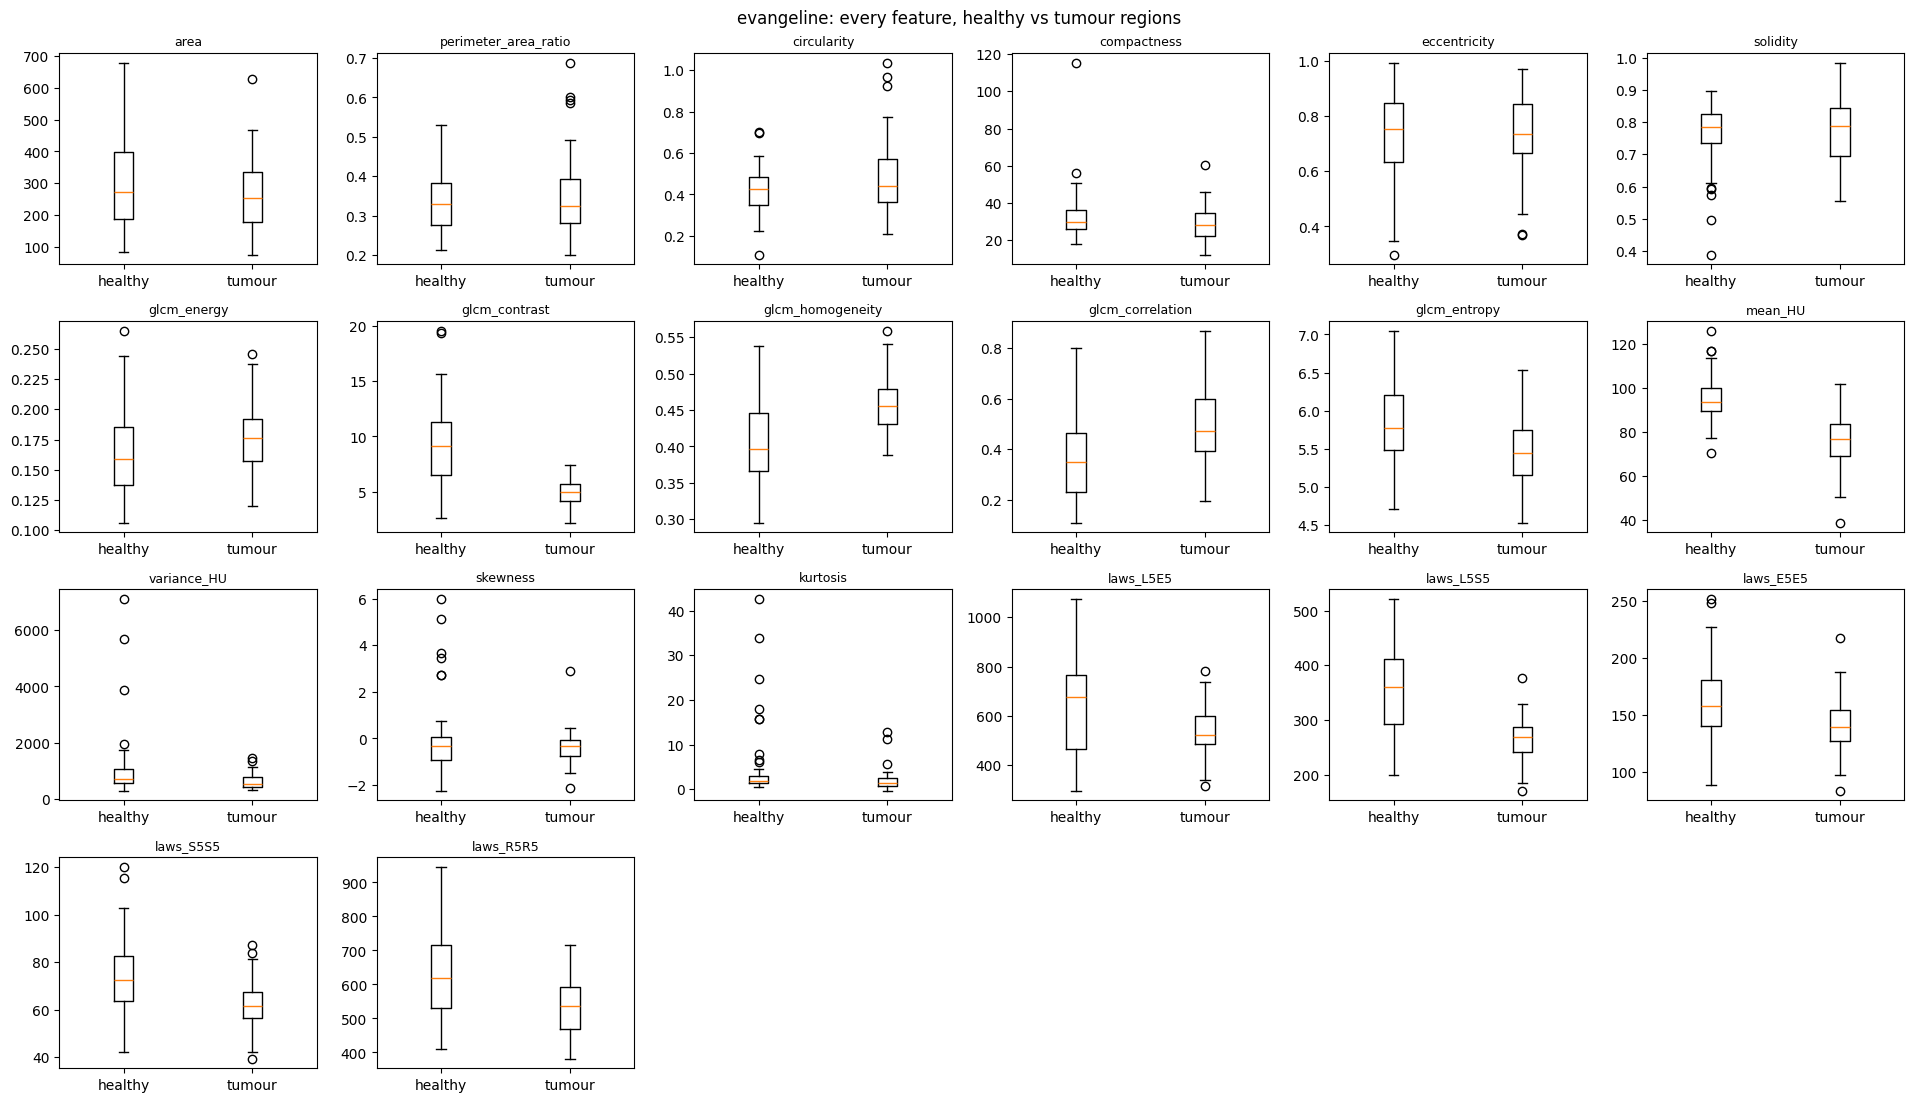

In [17]:
feature_names = list(features.columns[2:])
healthy = features[features.label == 0]
tumorous = features[features.label == 1]

# 1) box plots, healthy vs tumour
n_cols = 6
n_rows = int(np.ceil(len(feature_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows))
axes = axes.ravel()
for i in range(len(feature_names)):
    f = feature_names[i]
    axes[i].boxplot([healthy[f], tumorous[f]])
    axes[i].set_xticks([1, 2], ["healthy", "tumour"])
    axes[i].set_title(f, fontsize=9)
for i in range(len(feature_names), len(axes)):
    axes[i].axis("off")
plt.suptitle(f"{NAME}: every feature, healthy vs tumour regions")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p3_feature_boxplots.png", dpi=110)
plt.show()

In [18]:
# 2) Mann-Whitney U test per feature
test_rows = []
for f in feature_names:
    row = {}
    row["feature"] = f
    row["median healthy"] = healthy[f].median()
    row["median tumour"] = tumorous[f].median()
    row["p-value"] = mannwhitneyu(healthy[f], tumorous[f]).pvalue
    test_rows.append(row)
tests = pd.DataFrame(test_rows)
tests = tests.sort_values("p-value")
tests["significant (p < 0.05)"] = tests["p-value"] < 0.05
tests.to_csv(OUT + "/phase3_feature_tests.csv", index=False)
print("Mann-Whitney U, healthy vs tumour (smallest p first):")
print(tests.round(4).to_string(index=False))

Mann-Whitney U, healthy vs tumour (smallest p first):
             feature  median healthy  median tumour  p-value  significant (p < 0.05)
             mean_HU         93.7071        76.9418   0.0000                    True
       glcm_contrast          9.1480         4.9572   0.0000                    True
           laws_L5S5        360.5190       269.4678   0.0000                    True
    glcm_homogeneity          0.3961         0.4550   0.0000                    True
           laws_S5S5         72.4555        61.4294   0.0000                    True
           laws_R5R5        619.3779       536.4800   0.0000                    True
    glcm_correlation          0.3492         0.4728   0.0001                    True
           laws_E5E5        158.0858       139.2225   0.0002                    True
         variance_HU        702.9732       516.6882   0.0004                    True
        glcm_entropy          5.7792         5.4487   0.0004                    True
           

In [19]:
# 3) ablation: one feature group at a time, same tuned classifier, same grouped split
SHAPE = ["area", "perimeter_area_ratio", "circularity", "compactness", "eccentricity", "solidity"]
FIRST_ORDER = ["mean_HU", "variance_HU", "skewness", "kurtosis"]
GLCM = []
LAWS = []
for f in feature_names:
    if f.startswith("glcm_"):
        GLCM.append(f)
    if f.startswith("laws_"):
        LAWS.append(f)

feature_groups = {}
feature_groups["all features"] = feature_names
feature_groups["shape only"] = SHAPE
feature_groups["GLCM only"] = GLCM
feature_groups["first-order only"] = FIRST_ORDER
feature_groups["Laws texture only"] = LAWS

ablation_rows = []
for group_name in feature_groups:
    cols_used = feature_groups[group_name]
    idx = []
    for c in cols_used:
        idx.append(feature_names.index(c))
    clf = clone(search.best_estimator_)
    cv_result = cross_validate(clf, X_train[:, idx], y_train, groups=groups[idx_train], cv=cv5, scoring="f1")
    cv_f1 = cv_result["test_score"]
    clf.fit(X_train[:, idx], y_train)
    pred = clf.predict(X_test[:, idx])
    row = {}
    row["features"] = group_name
    row["n"] = len(idx)
    row["CV F1 mean"] = cv_f1.mean()
    row["CV F1 std"] = cv_f1.std()
    row["test accuracy"] = accuracy_score(y_test, pred)
    row["test F1"] = f1_score(y_test, pred, zero_division=0)
    ablation_rows.append(row)

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUT + "/phase3_ablation.csv", index=False)
print("\nAblation (same tuned classifier, same grouped split):")
print(ablation.round(3).to_string(index=False))


Ablation (same tuned classifier, same grouped split):
         features  n  CV F1 mean  CV F1 std  test accuracy  test F1
     all features 20       0.976      0.030          0.943    0.929
       shape only  6       0.244      0.180          0.600    0.000
        GLCM only  5       0.901      0.067          0.800    0.788
 first-order only  4       0.684      0.089          0.886    0.875
Laws texture only  5       0.878      0.160          0.771    0.667
